In [9]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

Import all the data

In [5]:
#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv('embedding_erl_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv('embedding_erl_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv('embedding_erl_3_1.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv('all_prot_erl_4_16_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv('all_prot_erl_4_16_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv('all_prot_erl_4_16_3_1.csv',header=None)

In [6]:
#times

all_time_stoch = pd.read_csv('all_time_stoch_4_16.csv',header=None)
all_time_at_stoch = pd.read_csv('all_time_at_stoch_4_16.csv',header=None)

This function ensures that the data has alternating cyclin E - cdc20 peaks. You will have to change find peaks based on the size of the window (peaks_E for example: 11*window_size+(window_size/2) and peaks_cdc: 17*window_size+(window_size/2)

In [7]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[1149], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[1749], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [8]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

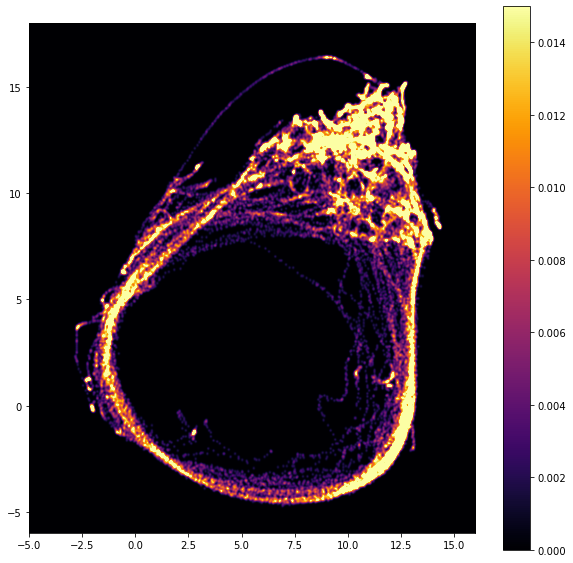

In [10]:
xmin, xmax = -5, 16
ymin, ymax = -6, 18

x = np.array(umap_win_erl_1_1[0])
y = np.array(umap_win_erl_1_1[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[-5,16], [-6,18]], density=True)
# Apply gaussian filter
sigma = [1, 1]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(10, 10)
plt.imshow(np.rot90(H2), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.015)
plt.colorbar()
